In [ ]:
!nvidia-smi


In [2]:
!pip install -q ultralytics albumentations

In [3]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="your key")
project = rf.workspace("vishi-sapra").project("object-detection-axukj")
version = project.version(10)
dataset = version.download("yolov8")


In [2]:
import glob
print(dataset.location)
for s in ["train", "valid", "test"]:
    print(s, len(glob.glob(f"{dataset.location}/{s}/images/*")))

/content/Object-detection-10
train 633
valid 165
test 100


In [3]:
!cat {dataset.location}/data.yaml

names:
- bus
- car
- person
- traffic signal
- truck
nc: 5
roboflow:
  license: CC BY 4.0
  project: object-detection-axukj
  url: https://universe.roboflow.com/vishi-sapra/object-detection-axukj/dataset/10
  version: 10
  workspace: vishi-sapra
test: ../test/images
train: ../train/images
val: ../valid/images


In [5]:
!pip install -q ultralytics albumentations

In [3]:
!unzip -q "/Object detection.v10-900-images-ka-version.yolov8.zip" -d /content/dataset

In [4]:
import glob, os
for s in ["train", "valid", "test"]:
    print(s, len(glob.glob(f"/content/dataset/{s}/images/*")))
print(os.listdir("/content/dataset"))

train 633
valid 165
test 100
['data.yaml', 'README.dataset.txt', 'valid', 'README.roboflow.txt', 'test', 'train']


In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
img = glob.glob("/content/dataset/valid/images/*")[0]
model.predict(img, save=True)

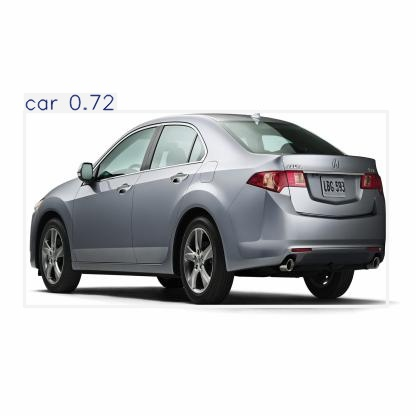

In [6]:
import glob
from IPython.display import Image, display
display(Image(glob.glob("/content/runs/detect/predict/*")[0]))

In [7]:
yaml_text = """
path: /content/dataset
train: train/images
val: valid/images
test: test/images
names:
  0: bus
  1: car
  2: person
  3: traffic signal
  4: truck
"""
open("/content/data_fixed.yaml", "w").write(yaml_text)

148

In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
results = model.train(
    data="/content/data_fixed.yaml",
    epochs=40,
    imgsz=416,
    batch=16,
    project="/content/runs_baseline",
    name="yolov8n_clean",
)

In [9]:
from google.colab import files
files.download("/content/runs_baseline/yolov8n_clean/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import os, glob, shutil, cv2, numpy as np
np.random.seed(0)

SRC = "/content/dataset"
split = "test" if glob.glob(f"{SRC}/test/images/*") else "valid"
print("Using split:", split, len(glob.glob(f"{SRC}/{split}/images/*")))

def add_fog(img, strength=0.5):
    h, w = img.shape[:2]
    noise = np.random.rand(h//8+1, w//8+1).astype(np.float32)
    noise = cv2.resize(noise, (w, h), interpolation=cv2.INTER_CUBIC)
    a = (strength * (0.7 + 0.3*noise))[..., None]
    out = img.astype(np.float32)*(1-a) + 220*a
    out = cv2.GaussianBlur(out, (5, 5), 0)
    return np.clip(out, 0, 255).astype(np.uint8)

def add_dark(img, factor=0.35):
    return np.clip(img.astype(np.float32)*factor, 0, 255).astype(np.uint8)

def make_set(name, fn=None):
    out = f"/content/{name}"
    os.makedirs(f"{out}/images", exist_ok=True)
    os.makedirs(f"{out}/labels", exist_ok=True)
    for p in glob.glob(f"{SRC}/{split}/images/*"):
        img = cv2.imread(p)
        cv2.imwrite(f"{out}/images/{os.path.basename(p)}", fn(img) if fn else img)
    for l in glob.glob(f"{SRC}/{split}/labels/*"):
        shutil.copy(l, f"{out}/labels/")
    open(f"/content/{name}.yaml", "w").write(f"""path: {out}
train: images
val: images
names:
  0: bus
  1: car
  2: person
  3: traffic signal
  4: truck
""")

make_set("clean")
make_set("fog", add_fog)
make_set("dark", add_dark)

Using split: test 100


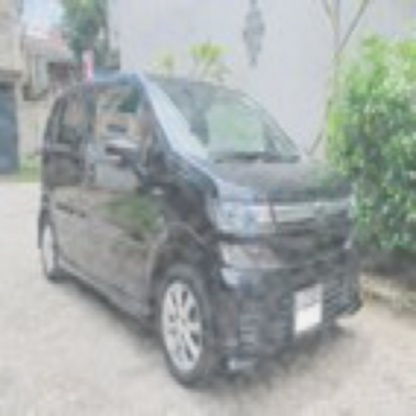

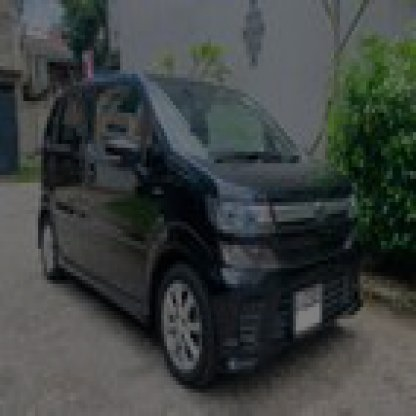

In [14]:
from IPython.display import Image, display
display(Image(glob.glob("/content/fog/images/*")[0]))
display(Image(glob.glob("/content/dark/images/*")[0]))

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/runs_baseline/yolov8n_clean/weights/best.pt")

for name in ["clean", "fog", "dark"]:
    m = model.val(data=f"/content/{name}.yaml", verbose=False, plots=False)
    print(name, "mAP50:", round(m.box.map50, 3), "mAP50-95:", round(m.box.map, 3))

In [16]:
import glob, os

def fix_labels(root):
    n = 0
    for f in glob.glob(f"{root}/*/labels/*.txt"):
        out, changed = [], False
        for line in open(f).read().strip().splitlines():
            p = line.split()
            if len(p) > 5:                      # polygon row -> bounding box
                xy = list(map(float, p[1:]))
                xs, ys = xy[0::2], xy[1::2]
                x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
                line = f"{p[0]} {(x1+x2)/2:.6f} {(y1+y2)/2:.6f} {x2-x1:.6f} {y2-y1:.6f}"
                changed = True
            out.append(line)
        if changed:
            open(f, "w").write("\n".join(out) + "\n")
            n += 1
    print("fixed files:", n)

fix_labels("/content/dataset")
!find /content/dataset -name "*.cache" -delete

fixed files: 29


In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(data="/content/data_fixed.yaml", epochs=40, imgsz=416, batch=16,
            project="/content/runs_baseline", name="yolov8n_clean2")


In [18]:
from google.colab import files
files.download("/content/runs_baseline/yolov8n_clean2/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os, cv2, shutil, numpy as np
np.random.seed(0)
SRC = "/content/dataset"

def add_fog(img, s):
    h, w = img.shape[:2]
    n = cv2.resize(np.random.rand(h//8+1, w//8+1).astype(np.float32), (w, h), interpolation=cv2.INTER_CUBIC)
    a = (s * (0.7 + 0.3*n))[..., None]
    out = cv2.GaussianBlur(img.astype(np.float32)*(1-a) + 220*a, (5, 5), 0)
    return np.clip(out, 0, 255).astype(np.uint8)

def add_dark(img, f):
    return np.clip(img.astype(np.float32)*f, 0, 255).astype(np.uint8)

def make_set(tag, split, fn=None):
    out = f"/content/eval/{tag}"
    shutil.rmtree(out, ignore_errors=True)
    os.makedirs(f"{out}/images"); os.makedirs(f"{out}/labels")
    for p in glob.glob(f"{SRC}/{split}/images/*"):
        img = cv2.imread(p)
        cv2.imwrite(f"{out}/images/{os.path.basename(p)}", fn(img) if fn else img)
    for l in glob.glob(f"{SRC}/{split}/labels/*"):
        shutil.copy(l, f"{out}/labels/")
    open(f"{out}.yaml", "w").write(f"path: {out}\ntrain: images\nval: images\nnames:\n  0: bus\n  1: car\n  2: person\n  3: traffic signal\n  4: truck\n")

conds = {
    "clean": None,
    "fog_0.5": lambda i: add_fog(i, 0.5), "fog_0.7": lambda i: add_fog(i, 0.7), "fog_0.85": lambda i: add_fog(i, 0.85),
    "dark_0.35": lambda i: add_dark(i, 0.35), "dark_0.2": lambda i: add_dark(i, 0.2), "dark_0.12": lambda i: add_dark(i, 0.12),
}

model = YOLO("/content/runs_baseline/yolov8n_clean2/weights/best.pt")
results = {}
for split in ["valid", "test"]:
    for c, fn in conds.items():
        tag = f"{split}_{c}"
        make_set(tag, split, fn)
        m = model.val(data=f"/content/eval/{tag}.yaml", verbose=False, plots=False)
        results[tag] = (round(m.box.map50, 3), round(m.box.map, 3))

print("\n=== RESULTS ===")
for k, v in results.items():
    print(f"{k:18s} mAP50: {v[0]}  mAP50-95: {v[1]}")

In [ ]:
m = model.val(data="/content/eval/test_clean.yaml", plots=False)
for i, n in model.names.items():
    print(n, round(m.box.maps[i], 3))
print("instances per class:", m.nt_per_class)

In [ ]:
import numpy as np
from ultralytics import YOLO

def eval_cp(mdl, tag):
    m = mdl.val(data=f"/content/eval/{tag}.yaml", verbose=False, plots=False)
    d = dict(zip(m.box.ap_class_index, m.box.ap50))
    return round(float(np.mean([d.get(1, 0), d.get(2, 0)])), 3)   # 1=car, 2=person

base = YOLO("/content/runs_baseline/yolov8n_clean2/weights/best.pt")
base_cp = {f"{s}_{c}": eval_cp(base, f"{s}_{c}") for s in ["valid", "test"] for c in conds}

print("\n=== BASELINE (car+person mAP50) ===")
for k, v in base_cp.items():
    print(f"{k:18s} {v}")

In [22]:
import random, shutil, glob, os, cv2, numpy as np
random.seed(1); np.random.seed(1)

AUG = "/content/dataset_aug"
shutil.rmtree(AUG, ignore_errors=True)
shutil.copytree("/content/dataset", AUG)
for c in glob.glob(f"{AUG}/**/*.cache", recursive=True):
    os.remove(c)

for p in glob.glob(f"{AUG}/train/images/*"):
    base = os.path.splitext(os.path.basename(p))[0]
    lbl = f"{AUG}/train/labels/{base}.txt"
    if not os.path.exists(lbl):
        continue
    img = cv2.imread(p)
    if random.random() < 0.5:
        out, tag = add_fog(img, random.uniform(0.3, 0.9)), "fog"
    else:
        out, tag = add_dark(img, random.uniform(0.12, 0.5)), "dark"
    cv2.imwrite(f"{AUG}/train/images/{base}_{tag}.jpg", out)
    shutil.copy(lbl, f"{AUG}/train/labels/{base}_{tag}.txt")

open("/content/data_aug.yaml", "w").write(f"""path: {AUG}
train: train/images
val: valid/images
test: test/images
names:
  0: bus
  1: car
  2: person
  3: traffic signal
  4: truck
""")
print("train images:", len(glob.glob(f"{AUG}/train/images/*")))

train images: 1266


In [ ]:
from ultralytics import YOLO
model_aug = YOLO("yolov8n.pt")
model_aug.train(data="/content/data_aug.yaml", epochs=40, imgsz=416, batch=16,
                project="/content/runs_baseline", name="yolov8n_aug")

In [24]:
from google.colab import files
files.download("/content/runs_baseline/yolov8n_clean2/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO
aug = YOLO("/content/runs_baseline/yolov8n_aug/weights/best.pt")
aug_cp = {k: eval_cp(aug, k) for k in base_cp}

print("\n=== BASELINE vs AUGMENTED (car+person mAP50) ===")
for k in base_cp:
    print(f"{k:18s} base: {base_cp[k]}  aug: {aug_cp[k]}")

split condition  baseline  augmented  delta
valid     clean     0.973      0.968 -0.005
valid   fog_0.5     0.953      0.961  0.008
valid   fog_0.7     0.882      0.949  0.067
valid  fog_0.85     0.758      0.932  0.174
valid dark_0.35     0.960      0.966  0.006
valid  dark_0.2     0.938      0.969  0.031
valid dark_0.12     0.891      0.962  0.071
 test     clean     0.974      0.976  0.002
 test   fog_0.5     0.945      0.967  0.022
 test   fog_0.7     0.914      0.966  0.052
 test  fog_0.85     0.808      0.979  0.171
 test dark_0.35     0.976      0.978  0.002
 test  dark_0.2     0.968      0.980  0.012
 test dark_0.12     0.934      0.980  0.046


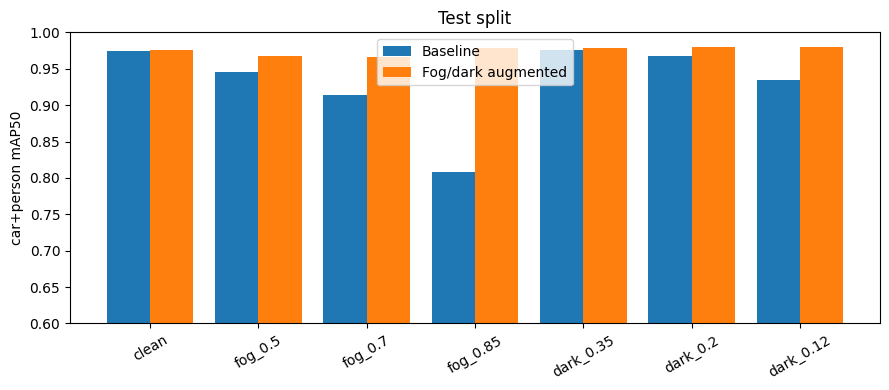

In [26]:
import pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("/content/repo/results/samples", exist_ok=True)

rows = []
for k in base_cp:
    s, c = k.split("_", 1)
    rows.append({"split": s, "condition": c, "baseline": base_cp[k],
                 "augmented": aug_cp[k], "delta": round(aug_cp[k] - base_cp[k], 3)})
df = pd.DataFrame(rows)
df.to_csv("/content/repo/results/results.csv", index=False)
print(df.to_string(index=False))

t = df[df.split == "test"]
x = range(len(t))
plt.figure(figsize=(9, 4))
plt.bar([i - 0.2 for i in x], t.baseline, 0.4, label="Baseline")
plt.bar([i + 0.2 for i in x], t.augmented, 0.4, label="Fog/dark augmented")
plt.xticks(list(x), t.condition, rotation=30)
plt.ylabel("car+person mAP50"); plt.ylim(0.6, 1.0)
plt.title("Test split"); plt.legend(); plt.tight_layout()
plt.savefig("/content/repo/results/test_comparison.png", dpi=150)

/tmp/ipykernel_6194/3408169558.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="lower right")


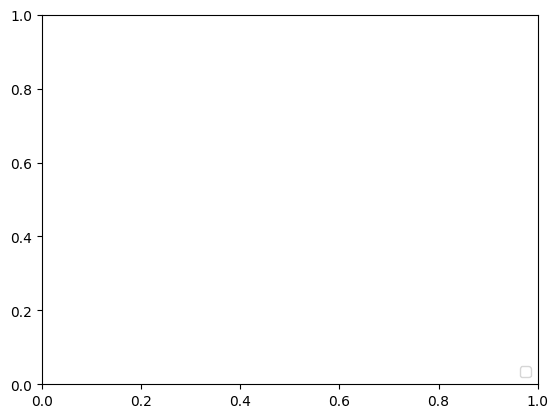

In [28]:
plt.legend(loc="lower right")

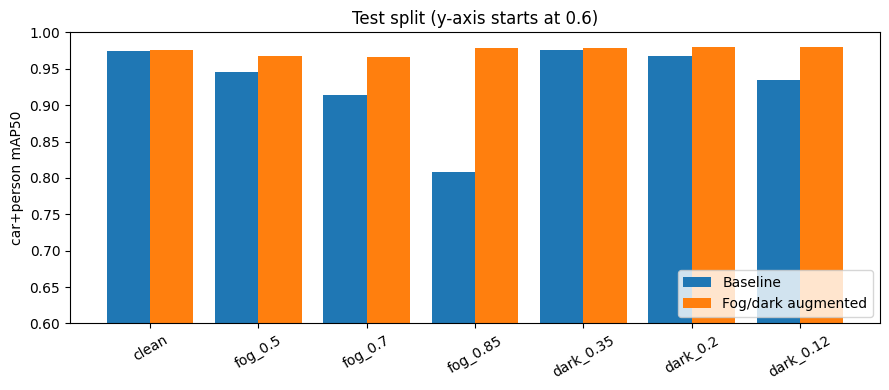

In [29]:
t = df[df.split == "test"]
x = range(len(t))
plt.figure(figsize=(9, 4))
plt.bar([i - 0.2 for i in x], t.baseline, 0.4, label="Baseline")
plt.bar([i + 0.2 for i in x], t.augmented, 0.4, label="Fog/dark augmented")
plt.xticks(list(x), t.condition, rotation=30)
plt.ylabel("car+person mAP50"); plt.ylim(0.6, 1.0)
plt.title("Test split (y-axis starts at 0.6)")
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("/content/repo/results/test_comparison.png", dpi=150)
plt.show()

In [30]:
import os
os.makedirs("/content/repo/results/samples", exist_ok=True)

In [31]:
import glob
from IPython.display import Image, display

files = sorted(glob.glob("/content/repo/results/samples/*.jpg"))
print(len(files), "images")
for f in files:
    print(f)
    display(Image(f))

0 images


baseline model: True
augmented model: True
fog images: 100
8 images
/content/repo/results/samples/fog085_0.jpg


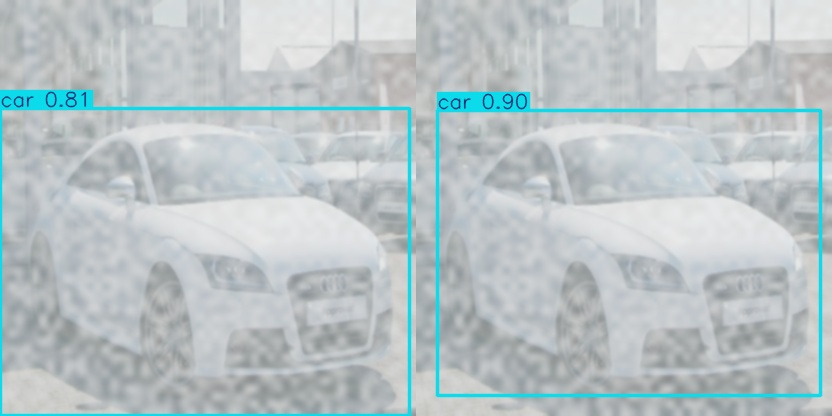

/content/repo/results/samples/fog085_1.jpg


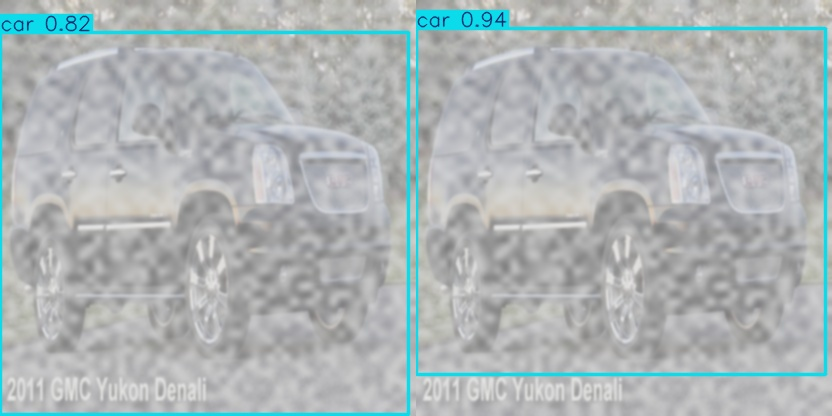

/content/repo/results/samples/fog085_2.jpg


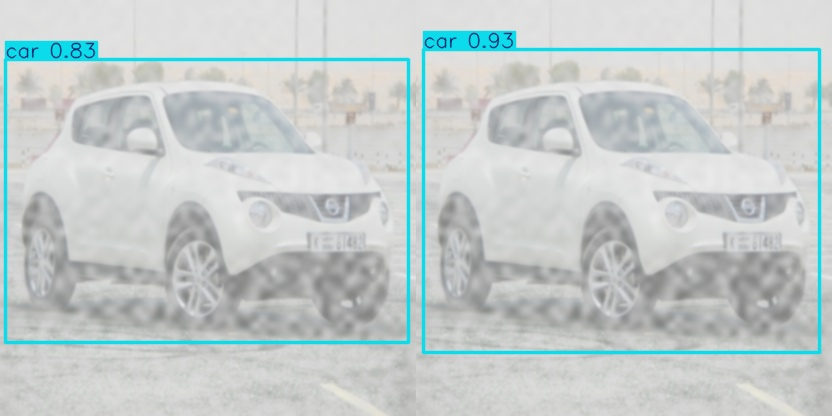

/content/repo/results/samples/fog085_3.jpg


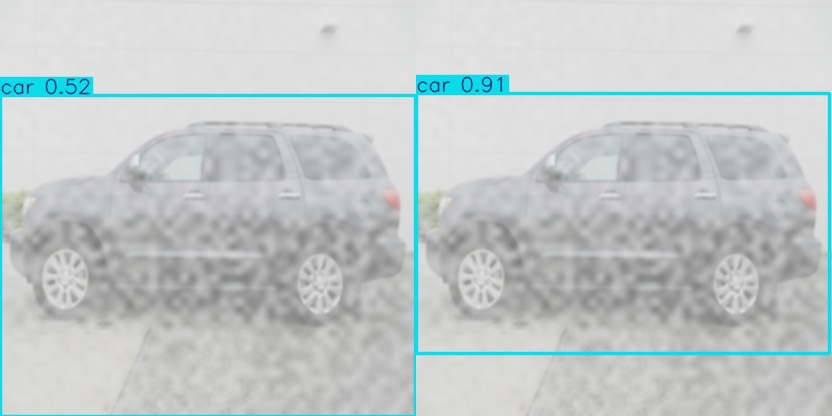

/content/repo/results/samples/fog085_4.jpg


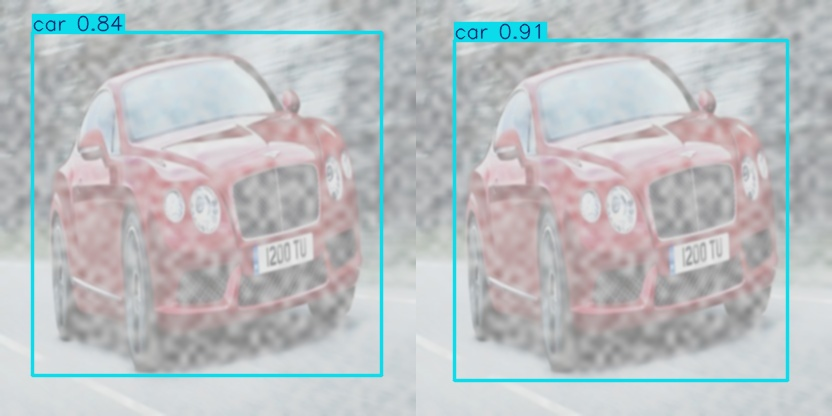

/content/repo/results/samples/fog085_5.jpg


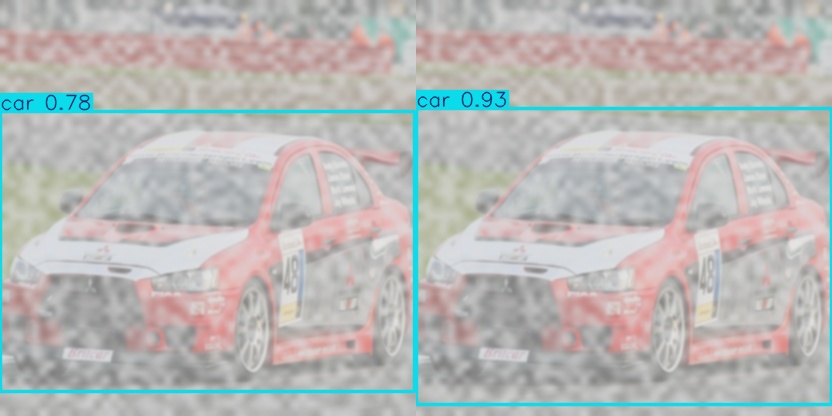

/content/repo/results/samples/fog085_6.jpg


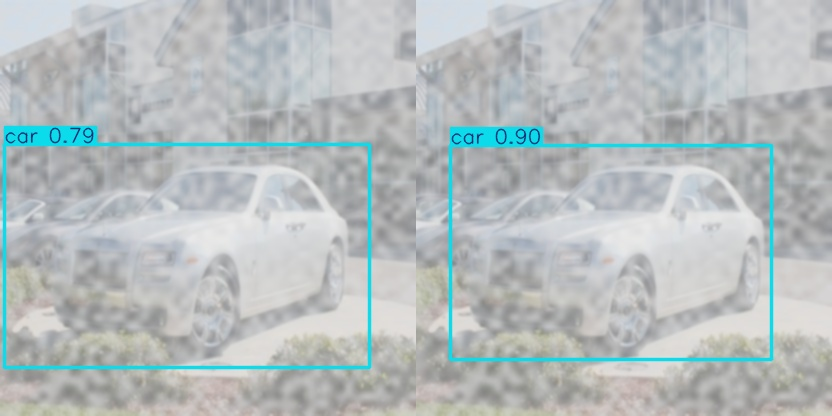

/content/repo/results/samples/fog085_7.jpg


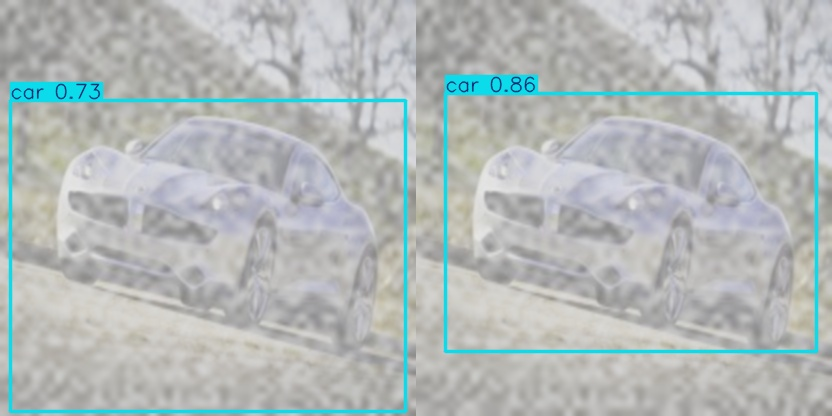

In [32]:
import os, glob, cv2, numpy as np
from ultralytics import YOLO
from IPython.display import Image, display

base_path = "/content/runs_baseline/yolov8n_clean2/weights/best.pt"
aug_path  = "/content/runs_baseline/yolov8n_aug/weights/best.pt"
src_dir   = "/content/eval/test_fog_0.85/images"
print("baseline model:", os.path.exists(base_path))
print("augmented model:", os.path.exists(aug_path))
print("fog images:", len(glob.glob(f"{src_dir}/*")))


base = YOLO(base_path)
aug  = YOLO(aug_path)


out_dir = "/content/repo/results/samples"
os.makedirs(out_dir, exist_ok=True)
imgs = sorted(glob.glob(f"{src_dir}/*"))[:8]
for i, p in enumerate(imgs):
    a = cv2.resize(base.predict(p, conf=0.25, verbose=False)[0].plot(), (416, 416))
    b = cv2.resize(aug.predict(p, conf=0.25, verbose=False)[0].plot(), (416, 416))
    cv2.imwrite(f"{out_dir}/fog085_{i}.jpg", np.hstack([a, b]))

files = sorted(glob.glob(f"{out_dir}/*.jpg"))
print(len(files), "images")
for f in files:
    print(f)
    display(Image(f))

In [ ]:
import os, glob
from ultralytics import YOLO

base = YOLO("/content/runs_baseline/yolov8n_clean2/weights/best.pt")
aug  = YOLO("/content/runs_baseline/yolov8n_aug/weights/best.pt")
src  = "/content/eval/test_fog_0.85"
CAR, PERSON = 1, 2  # class ids in this dataset

def to_xyxy(b):
    """Convert normalized (cx, cy, w, h) to (x1, y1, x2, y2)."""
    x, y, w, h = b
    return [x - w/2, y - h/2, x + w/2, y + h/2]

def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

def load_gt(label_path):
    """Load ground-truth car/person boxes from a YOLO label file."""
    boxes = []
    if os.path.exists(label_path):
        for line in open(label_path).read().strip().splitlines():
            p = line.split()
            if len(p) == 5 and int(p[0]) in (CAR, PERSON):
                boxes.append((int(p[0]), to_xyxy(list(map(float, p[1:])))))
    return boxes

def score(model, img_path, gts, conf=0.25, iou_thr=0.5):
    """Return (hits, misses, extras) for one image."""
    r = model.predict(img_path, conf=conf, verbose=False)[0]
    preds = sorted(
        [(float(cf), int(c), to_xyxy(b)) for cf, c, b in
         zip(r.boxes.conf.tolist(), r.boxes.cls.tolist(), r.boxes.xywhn.tolist())
         if int(c) in (CAR, PERSON)],
        reverse=True)  # highest confidence first
    used, hits = set(), 0
    for _, c, b in preds:
        best, best_i = 0, -1
        for i, (gc, gb) in enumerate(gts):
            if i in used or gc != c:
                continue
            v = iou(b, gb)
            if v > best:
                best, best_i = v, i
        if best >= iou_thr:
            used.add(best_i)
            hits += 1
    return hits, len(gts) - hits, len(preds) - hits

rows = []
for p in sorted(glob.glob(f"{src}/images/*")):
    name = os.path.splitext(os.path.basename(p))[0]
    gts = load_gt(f"{src}/labels/{name}.txt")
    rows.append((name[:22], len(gts), score(base, p, gts), score(aug, p, gts)))

print("First 8 images (hit / miss / extra)")
print(f"{'image':24s}{'GT':>4s}   {'baseline':>12s}   {'augmented':>12s}")
for n, g, b, a in rows[:8]:
    print(f"{n:24s}{g:>4d}   {b[0]:>4d}/{b[1]}/{b[2]}      {a[0]:>4d}/{a[1]}/{a[2]}")

print("\nTotals over all 100 images")
for label, k in [("baseline", 2), ("augmented", 3)]:
    h = sum(r[k][0] for r in rows)
    m = sum(r[k][1] for r in rows)
    e = sum(r[k][2] for r in rows)
    print(f"{label:10s} hits={h}  misses={m}  extras={e}  (GT total={sum(r[1] for r in rows)})")

print("\nTop 5 images where the two models differ most (baseline misses minus augmented misses)")
top = sorted(rows, key=lambda r: r[2][1] - r[3][1], reverse=True)[:5]
for n, g, b, a in top:
    print(f"{n:24s} GT={g}  baseline misses={b[1]}  augmented misses={a[1]}")

In [34]:
import os, glob
from ultralytics import YOLO

base = YOLO("/content/runs_baseline/yolov8n_clean2/weights/best.pt")
aug  = YOLO("/content/runs_baseline/yolov8n_aug/weights/best.pt")
src  = "/content/eval/test_fog_0.85"
CAR, PERSON = 1, 2  # class ids in this dataset

def to_xyxy(b):
    """Convert normalized (cx, cy, w, h) to (x1, y1, x2, y2)."""
    x, y, w, h = b
    return [x - w/2, y - h/2, x + w/2, y + h/2]

def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

def load_gt(label_path):
    """Load ground-truth car/person boxes from a YOLO label file."""
    boxes = []
    if os.path.exists(label_path):
        for line in open(label_path).read().strip().splitlines():
            p = line.split()
            if len(p) == 5 and int(p[0]) in (CAR, PERSON):
                boxes.append((int(p[0]), to_xyxy(list(map(float, p[1:])))))
    return boxes

def score(model, img_path, gts, conf=0.25, iou_thr=0.5):
    """Return (hits, misses, extras) for one image."""
    r = model.predict(img_path, conf=conf, verbose=False)[0]
    preds = sorted(
        [(float(cf), int(c), to_xyxy(b)) for cf, c, b in
         zip(r.boxes.conf.tolist(), r.boxes.cls.tolist(), r.boxes.xywhn.tolist())
         if int(c) in (CAR, PERSON)],
        reverse=True)  # highest confidence first
    used, hits = set(), 0
    for _, c, b in preds:
        best, best_i = 0, -1
        for i, (gc, gb) in enumerate(gts):
            if i in used or gc != c:
                continue
            v = iou(b, gb)
            if v > best:
                best, best_i = v, i
        if best >= iou_thr:
            used.add(best_i)
            hits += 1
    return hits, len(gts) - hits, len(preds) - hits

rows = []
for p in sorted(glob.glob(f"{src}/images/*")):
    name = os.path.splitext(os.path.basename(p))[0]
    gts = load_gt(f"{src}/labels/{name}.txt")
    rows.append((name[:22], len(gts), score(base, p, gts), score(aug, p, gts)))

print("First 8 images (hit / miss / extra)")
print(f"{'image':24s}{'GT':>4s}   {'baseline':>12s}   {'augmented':>12s}")
for n, g, b, a in rows[:8]:
    print(f"{n:24s}{g:>4d}   {b[0]:>4d}/{b[1]}/{b[2]}      {a[0]:>4d}/{a[1]}/{a[2]}")

print("\nTotals over all 100 images")
for label, k in [("baseline", 2), ("augmented", 3)]:
    h = sum(r[k][0] for r in rows)
    m = sum(r[k][1] for r in rows)
    e = sum(r[k][2] for r in rows)
    print(f"{label:10s} hits={h}  misses={m}  extras={e}  (GT total={sum(r[1] for r in rows)})")

print("\nTop 5 images where the two models differ most (baseline misses minus augmented misses)")
top = sorted(rows, key=lambda r: r[2][1] - r[3][1], reverse=True)[:5]
for n, g, b, a in top:
    print(f"{n:24s} GT={g}  baseline misses={b[1]}  augmented misses={a[1]}")

First 8 images (hit / miss / extra)
image                     GT       baseline      augmented
00001_jpg.rf.a9b6055c6     2      1/1/0         1/1/0
00023_jpg.rf.0abe63861     1      1/0/0         1/0/0
00024_jpg.rf.a57782e12     1      1/0/0         1/0/0
00045_jpg.rf.4dc7e0410     1      1/0/0         1/0/0
00117_jpg.rf.f2dfbba13     1      1/0/0         1/0/0
00246_jpg.rf.ac7e661fc     1      1/0/0         1/0/0
00248_jpg.rf.d5becb665     2      1/1/0         1/1/0
00252_jpg.rf.10d8e6056     1      1/0/0         1/0/0

Totals over all 100 images
baseline   hits=92  misses=56  extras=18  (GT total=148)
augmented  hits=141  misses=7  extras=21  (GT total=148)

Top 5 images where the two models differ most (baseline misses minus augmented misses)
Screen-Shot-2022-04-14   GT=5  baseline misses=4  augmented misses=0
66_jpg.rf.7a48a49c6061   GT=3  baseline misses=3  augmented misses=0
Screen-Shot-2022-04-14   GT=5  baseline misses=3  augmented misses=0
Screen-Shot-2022-04-14   GT=6  basel

/content/repo/results/samples/baseline_misses_augmented_ok.jpg


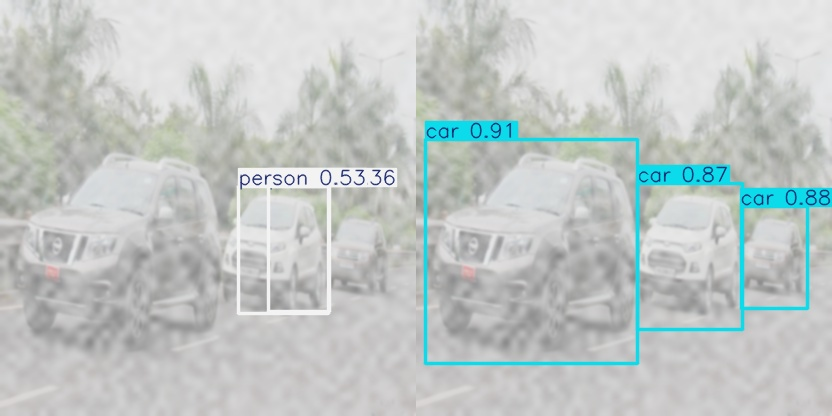

/content/repo/results/samples/both_miss_one.jpg


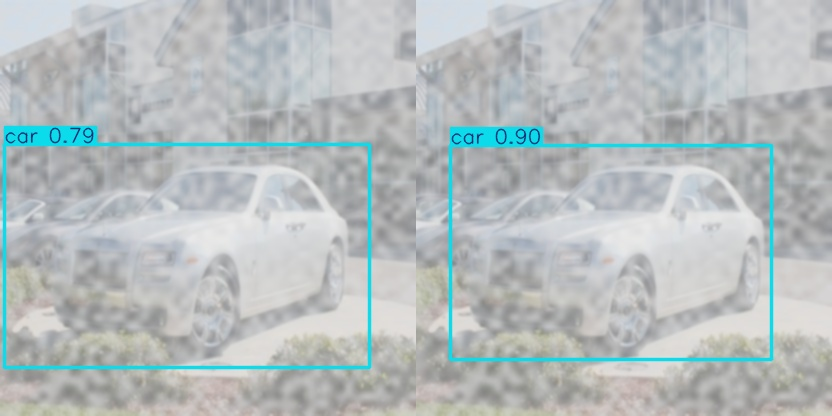

/content/repo/results/samples/both_ok.jpg


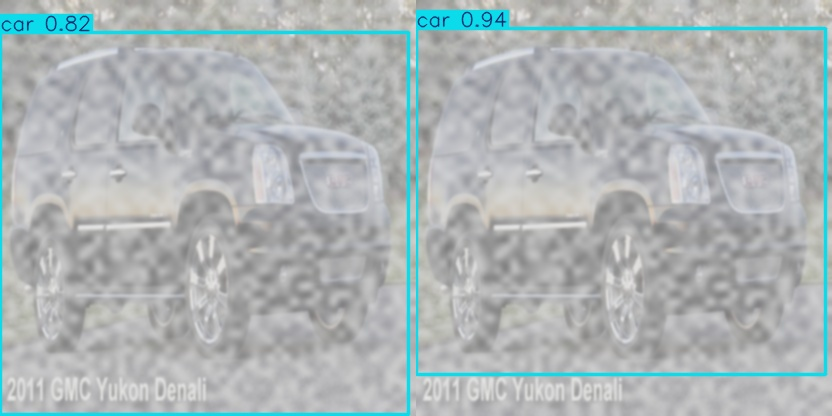

In [35]:
import glob, os, cv2, numpy as np
from IPython.display import Image, display

out = "/content/repo/results/samples"
os.makedirs(out, exist_ok=True)
for f in glob.glob(f"{out}/*.jpg"):
    os.remove(f)  # clear old samples

# prefix of the image file name -> label used in the output file name
picks = {
    "66_jpg.rf.7a48a49c6061":  "baseline_misses_augmented_ok",
    "00023_jpg.rf.0abe63861":  "both_ok",
    "00248_jpg.rf.d5becb665":  "both_miss_one",
}

for prefix, tag in picks.items():
    matches = glob.glob(f"/content/eval/test_fog_0.85/images/{prefix}*")
    if not matches:
        print("not found:", prefix)
        continue
    p = matches[0]
    left = cv2.resize(base.predict(p, conf=0.25, verbose=False)[0].plot(), (416, 416))
    right = cv2.resize(aug.predict(p, conf=0.25, verbose=False)[0].plot(), (416, 416))
    cv2.imwrite(f"{out}/{tag}.jpg", np.hstack([left, right]))

for f in sorted(glob.glob(f"{out}/*.jpg")):
    print(f)
    display(Image(f))

In [37]:
import os
d = "/content/repo/results/samples"
os.rename(f"{d}/baseline_misses_augmented_ok.jpg", f"{d}/baseline_errors_augmented_ok.jpg")
print(os.listdir(d))

['both_ok.jpg', 'both_miss_one.jpg', 'baseline_errors_augmented_ok.jpg']
